# BiSI XRD analysis

Loads the BiSI synthesis table and NOMAD XRD archives, matches peaks against the configured BiSI and candidate impurity RTF cards, computes sample metrics, and saves BiSI-specific outputs. The Le Bail section is exploratory only; it uses the supplied BiSI CIFs and does not report quantitative phase fractions.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from xrd_bo_optimization_tf.config import (
    FIGURES_DIR,
    GENERATED_XRD_METRICS_CSV,
    NOMAD_STAGING_DIR,
    NOMAD_SYNTHESIS_CSV,
    SYNTHESIS_CSV,
    XRD_METRICS_CSV,
)
from xrd_bo_optimization_tf.phase_matching import analyze_pattern, load_reference_cards
from xrd_bo_optimization_tf.plotting import plot_all_xrd_patterns, plot_xrd_series
from xrd_bo_optimization_tf.xrd_io import load_xrd_data

# Prefer the complete NOMAD synthesis database; fall back to the legacy CSV.
synthesis_path = NOMAD_SYNTHESIS_CSV if NOMAD_SYNTHESIS_CSV.is_file() else SYNTHESIS_CSV
df_synth_csv = pd.read_csv(synthesis_path)
print(f'Synthesis source: {synthesis_path} ({len(df_synth_csv)} samples)')

references = load_reference_cards()
# XRD scans come from the NOMAD archives staged by notebook 1 (source='nomad').
xrd_raw = load_xrd_data(
    df_synth_csv['sample_id'].astype(str).tolist(),
    source='nomad',
    nomad_archive_root=NOMAD_STAGING_DIR,
)
print(f'Loaded {len(xrd_raw)} XRD scans for {len(df_synth_csv)} synthesis records')

Synthesis source: /home/nomad-lanasc/bisi-xrd-optimization/data/processed/bisi_synthesis_database_nomad.csv (41 samples)
Loaded 33 XRD scans for 41 synthesis records


In [2]:
xrd_results = {
    sample_id: analyze_pattern(scan['two_theta'], scan['intensity'], references)
    for sample_id, scan in xrd_raw.items()
}

metrics_path = (
    GENERATED_XRD_METRICS_CSV
    if GENERATED_XRD_METRICS_CSV.is_file()
    else XRD_METRICS_CSV
)
if metrics_path.is_file():
    existing_metrics = pd.read_csv(metrics_path)
else:
    existing_metrics = pd.DataFrame(
        columns=[
            'sample_id', 'series', 'crystallinity', 'primary_fwhm',
            'phase_purity', 'n_detected_peaks', 'n_target_matches',
        ]
    )

if xrd_results:
    synthesis_lookup = df_synth_csv.drop_duplicates('sample_id').set_index('sample_id')
    rows = []
    process_columns = (
        'spin_speed_rpm', 'soft_bake_temp_c', 'hard_bake_temp_c',
        'bismuth_concentration_mol_l', 's_to_bi_molar_ratio',
        'i_to_bi_molar_ratio',
    )
    for sample_id, result in sorted(xrd_results.items()):
        if sample_id not in synthesis_lookup.index:
            continue
        synthesis = synthesis_lookup.loc[sample_id]
        rows.append({
            'sample_id': sample_id,
            'series': synthesis['series'],
            'crystallinity': result['crystallinity'],
            'primary_fwhm': result['primary_fwhm'],
            'phase_purity': result['phase_purity'],
            'n_detected_peaks': result['n_detected_peaks'],
            'n_target_matches': result['n_target_matches'],
            **{column: synthesis.get(column) for column in process_columns},
        })
    analyzed_metrics = pd.DataFrame(rows)
    if not analyzed_metrics.empty:
        updated_ids = set(analyzed_metrics['sample_id'].astype(str))
        existing_metrics = existing_metrics.loc[
            ~existing_metrics['sample_id'].astype(str).isin(updated_ids)
        ]
        df_metrics = pd.concat([existing_metrics, analyzed_metrics], ignore_index=True)
        GENERATED_XRD_METRICS_CSV.parent.mkdir(parents=True, exist_ok=True)
        df_metrics.to_csv(GENERATED_XRD_METRICS_CSV, index=False)
        print(f'Wrote {len(analyzed_metrics)} BiSI scan metrics to {GENERATED_XRD_METRICS_CSV}')
    else:
        df_metrics = existing_metrics
        print('No XRD scans matched the BiSI synthesis table; kept existing metrics')
else:
    df_metrics = existing_metrics
    print(f'No XRD scans found; loaded existing metrics from {metrics_path}')

df_metrics.head()

Wrote 33 BiSI scan metrics to /home/nomad-lanasc/bisi-xrd-optimization/data/results/bisi_xrd_analysis_metrics.csv


,sample_id,series,crystallinity,primary_fwhm,phase_purity,n_detected_peaks,n_target_matches,spin_speed_rpm,soft_bake_temp_c,hard_bake_temp_c,bismuth_concentration_mol_l,s_to_bi_molar_ratio,i_to_bi_molar_ratio
0,260408A1,260408A,2.856941,0.350025,1.0,2,2,3000.0,150.0,170.0,0.533863,0.982289,1.046516
1,260408A2,260408A,3.465627,0.288548,1.0,4,4,3000.0,150.0,190.0,0.533863,0.982289,1.046516
2,260408A3,260408A,3.618698,0.276342,1.0,1,1,3000.0,150.0,210.0,0.533863,0.982289,1.046516
3,260408A4,260408A,NaN,NaN,NaN,0,0,3000.0,150.0,150.0,0.533863,0.982289,1.046516
4,260408A5,260408A,NaN,NaN,NaN,0,0,3000.0,150.0,230.0,0.533863,0.982289,1.046516


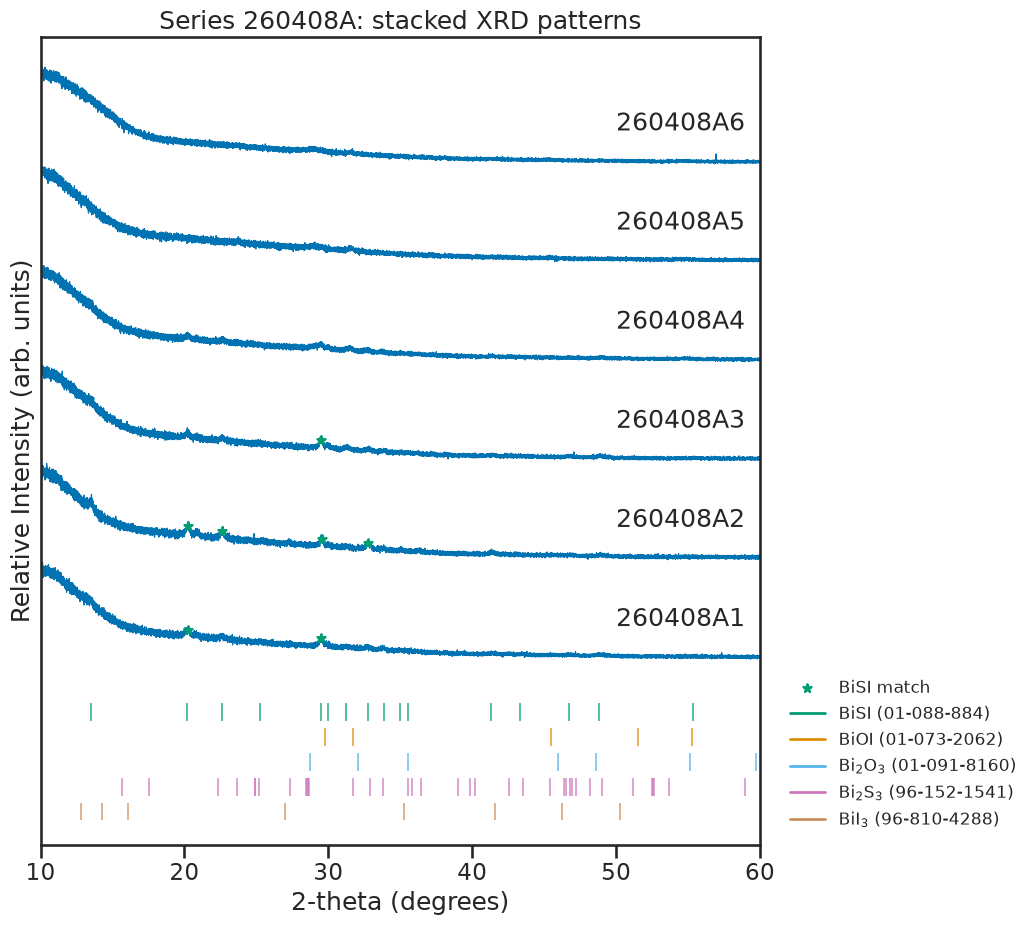

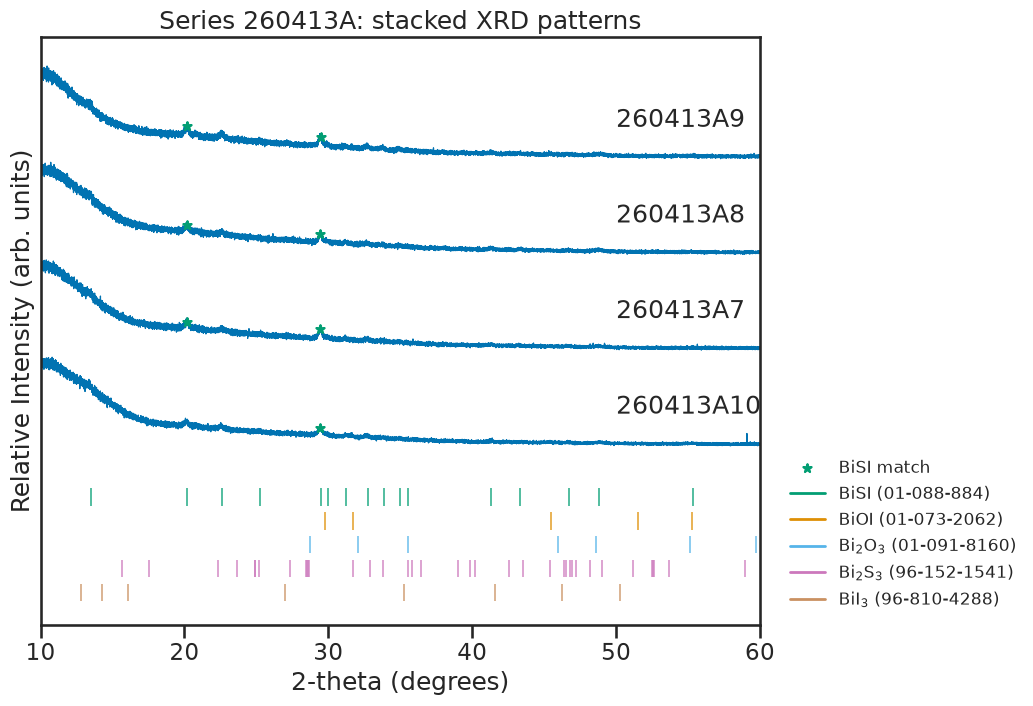

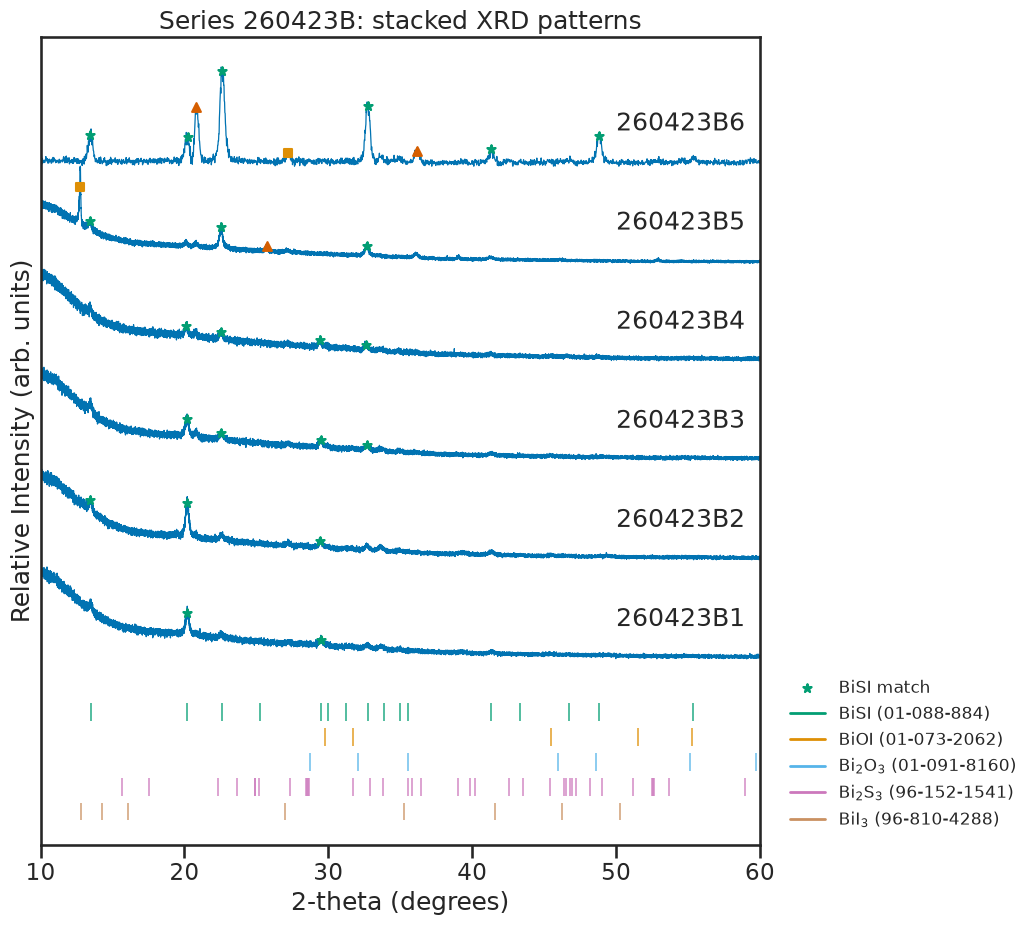

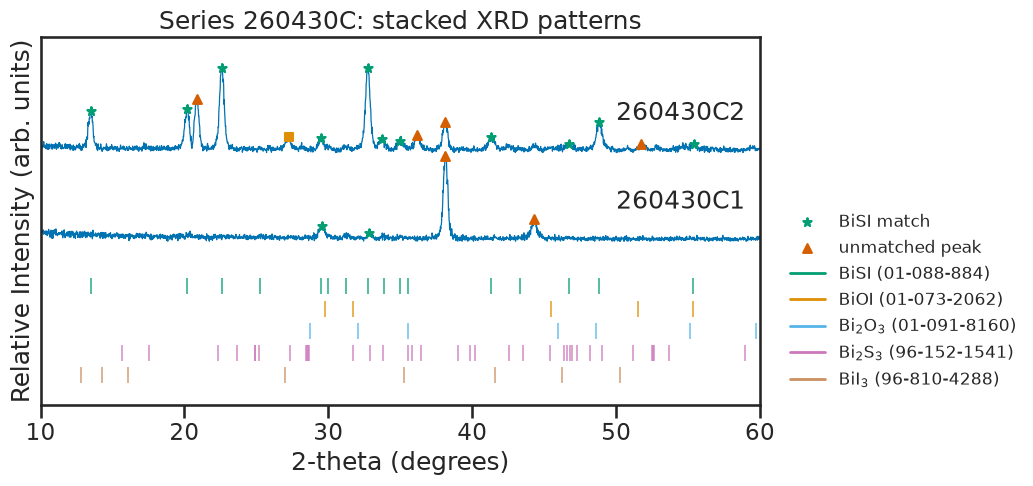

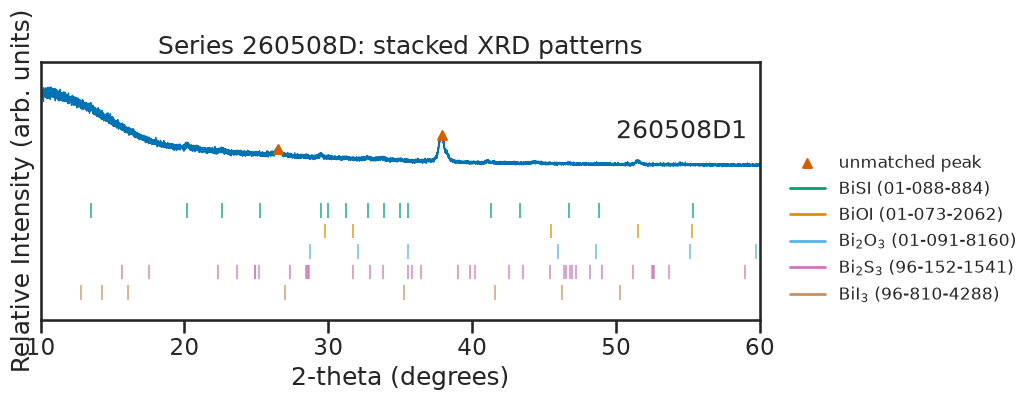

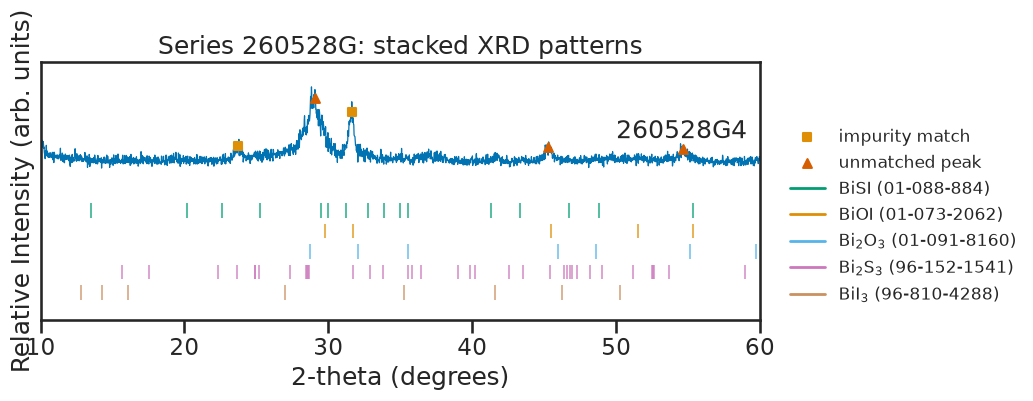

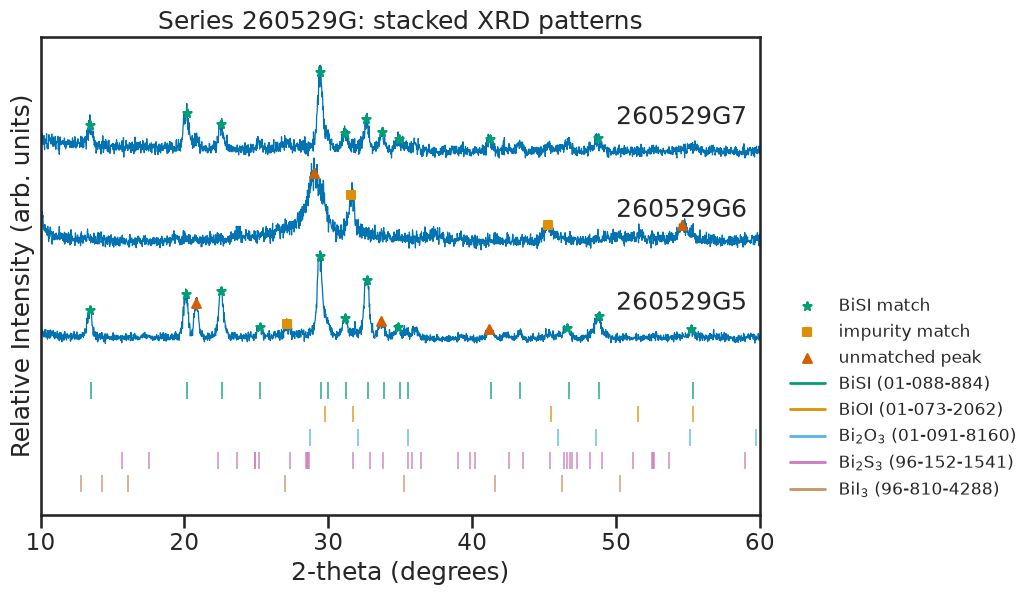

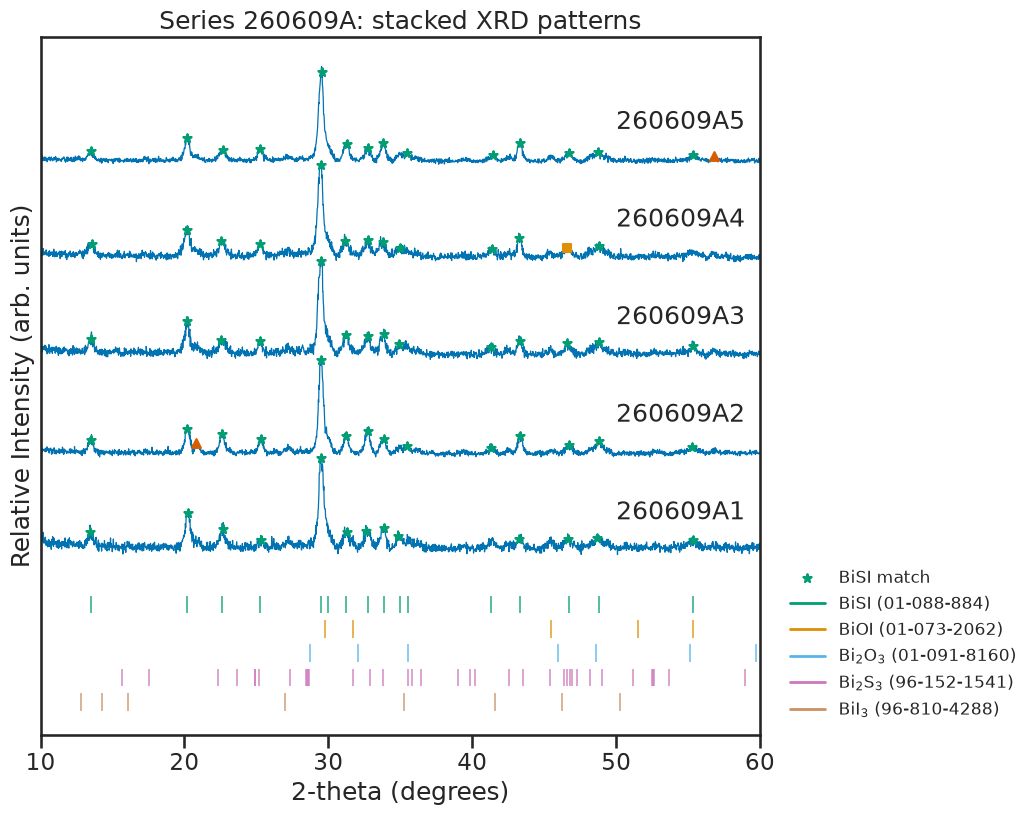

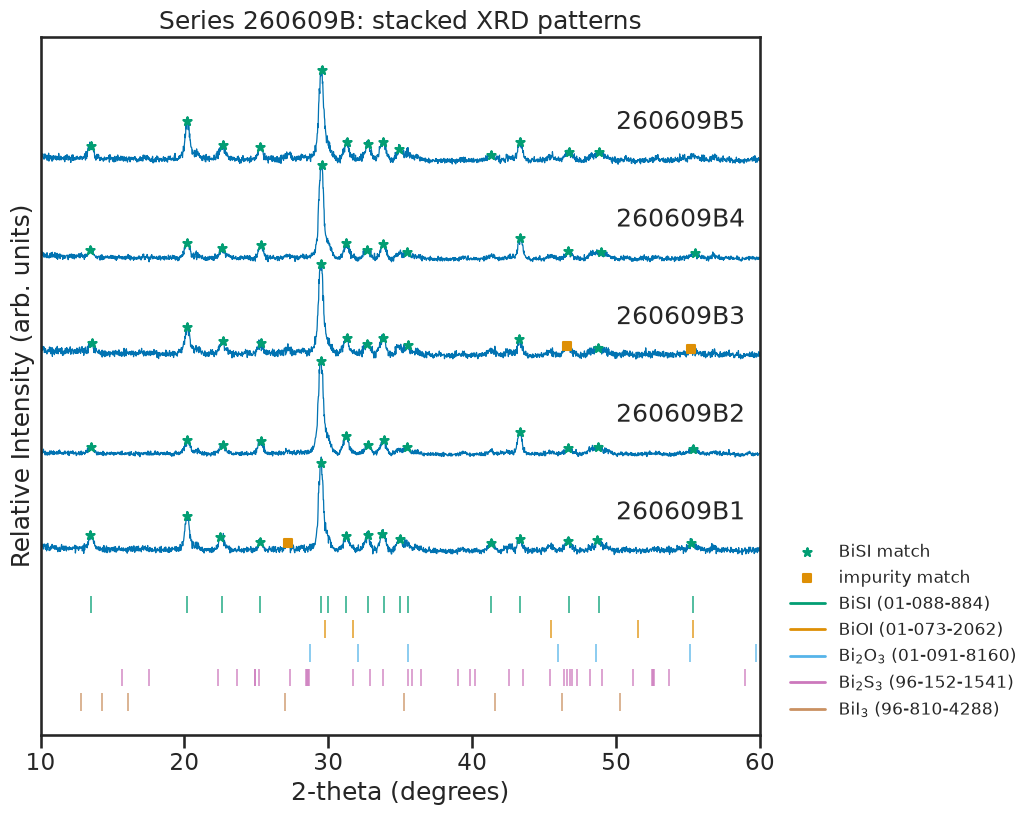

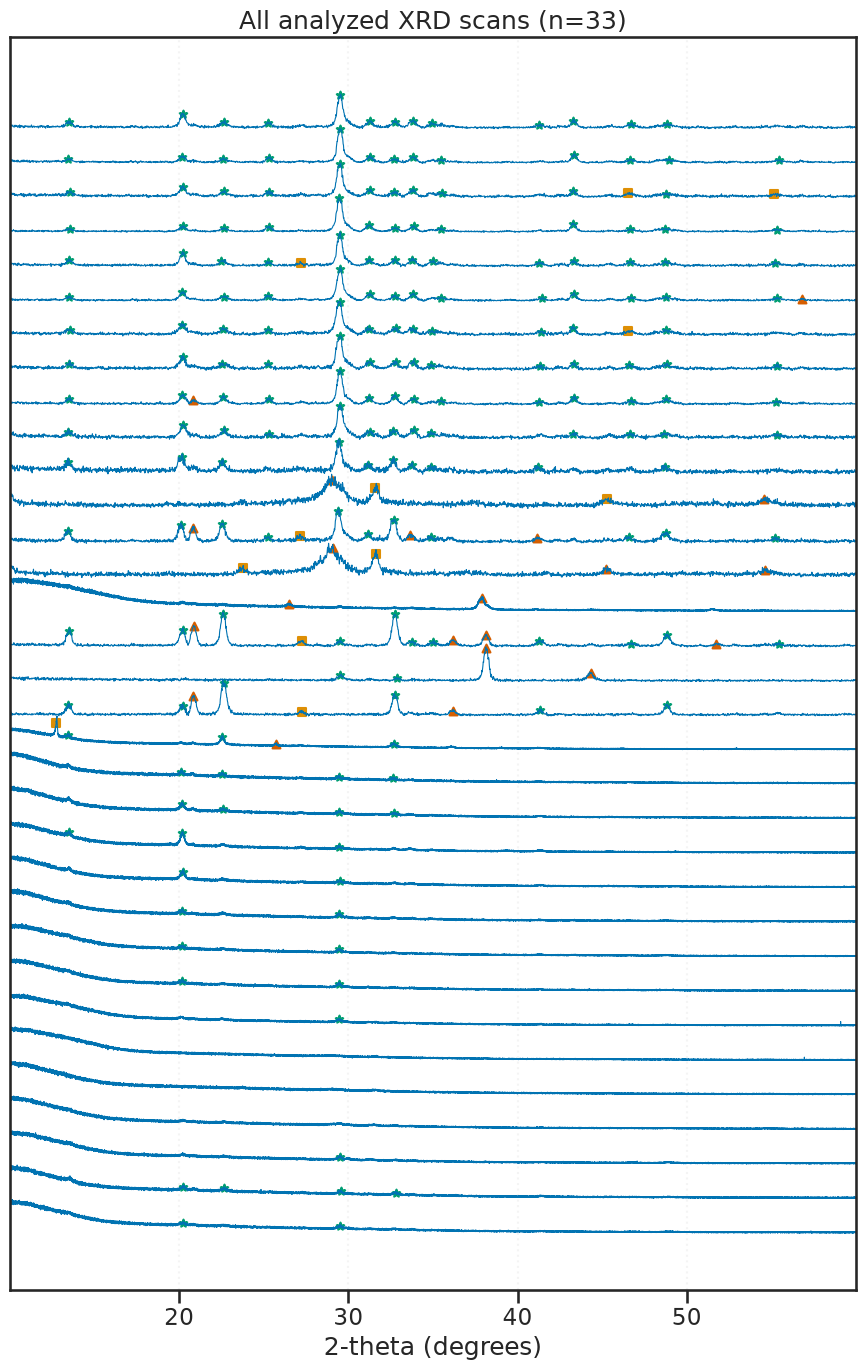

In [3]:
series_figures = plot_xrd_series(xrd_results, df_metrics, references)
all_scans_figure = plot_all_xrd_patterns(
    xrd_results,
    df_metrics,
    output_path=FIGURES_DIR / "bisi_xrd_all_samples.png",
)
if series_figures or all_scans_figure is not None:
    plt.show()
else:
    print("Plots will be available when BiSI XRD scans are present in the NOMAD archive set.")

In [4]:
summary_columns = [column for column in (
    'crystallinity', 'phase_purity', 'primary_fwhm', 'n_detected_peaks',
) if column in df_metrics]
df_metrics.groupby('series')[summary_columns].agg(['count', 'mean', 'min', 'max']).round(3)

crystallinity                               phase_purity            \
                count      mean       min       max        count      mean   
series                                                                       
260408A             3  3.313755  2.856941  3.618698            3       1.0   
260413A             4  3.443882   3.28266  3.698641            4       1.0   
260423B             6  4.229847  2.536005  6.233274            6  0.937267   
260430C             2  2.382146  2.100522  2.663771            2  0.976858   
260508D             0       NaN       NaN       NaN            0       NaN   
260528G             0       NaN       NaN       NaN            1       0.0   
260529G             2  2.375791  2.368384  2.383197            3  0.648979   
260609A             5  2.386201   2.26425  2.551731            5  0.989833   
260609B             5   2.45506   2.38009  2.534936            5  0.974014   

                       primary_fwhm                                \
              min  max        count      mean       min       max   
series                                                              
260408A       1.0  1.0            3  0.304972  0.276342  0.350025   
260413A       1.0  1.0            4  0.290936   0.27037  0.304631   
260423B  0.678297  1.0            6  0.259004  0.160429  0.394321   
260430C  0.953716  1.0            2   0.42574  0.375408  0.476072   
260508D       NaN  NaN            0       NaN       NaN       NaN   
260528G       0.0  0.0            0       NaN       NaN       NaN   
260529G       0.0  1.0            2  0.420917  0.419604  0.422229   
260609A  0.949163  1.0            5  0.419823  0.391891  0.441647   
260609B  0.908634  1.0            5  0.407568  0.394487  0.420152   

        n_detected_peaks                    
                   count      mean min max  
series                                      
260408A                6  1.166667   0   4  
260413A                4      1.75   1   2  
260423B                6       4.5   2   9  
260430C                2      10.0   4  16  
260508D                1       2.0   2   2  
260528G                1       5.0   5   5  
260529G                3  9.666667   4  15  
260609A                5      14.0  13  15  
260609B                5      13.4  13  15

Optional exploratory multiphase Le Bail fit using the BiSI target and configured BiSI impurity CIFs. The available rietx geometry is a Bragg–Brentano profile proxy rather than fixed-incidence GIXRD, so interpret fits as qualitative only; do not infer quantitative phase fractions.

In [6]:
import json
import re
import time
from pathlib import Path

import numpy as np
import rietx as rx

from xrd_bo_optimization_tf.config import NOMAD_STAGING_DIR, OUTPUTS_DIR

LEBAIL_OUTPUT_DIR = OUTPUTS_DIR / "rietx_lebail_bisi"
LEBAIL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cif_phases = (("BiSI", "BiSI.cif"), ("BiOI", "BiIO.cif"), ("Bi2O3", "Bi2O3.cif"), ("Bi2S3", "Bi2S3.cif"), ("BiI3", "BiI3.cif"))
phase_display_names = {"BiSI": "BiSI", "BiOI": "BiOI", "Bi2O3": "Bi₂O₃", "Bi2S3": "Bi₂S₃", "BiI3": "BiI₃"}
cif_dir = Path.cwd().parent / "data" / "cif_files"
phase_templates = []
for phase_key, cif_name in cif_phases:
    cif_structure = rx.Structure.from_cif(cif_dir / cif_name, phase_name=phase_display_names[phase_key])
    phase_templates.extend(cif_structure.phases)

measurement_metadata = {}
for archive_path in sorted(NOMAD_STAGING_DIR.rglob("*.archive.json")):
    try:
        archive_data = json.loads(archive_path.read_text(encoding="utf-8")).get("data", {})
    except (OSError, json.JSONDecodeError):
        continue
    if not isinstance(archive_data, dict) or "ELNXRayDiffraction" not in str(archive_data.get("m_def", "")):
        continue
    tokens = str(archive_data.get("name", "")).split()
    sample_id = tokens[0] if tokens else ""
    if sample_id not in xrd_raw or sample_id in measurement_metadata:
        continue
    if "Grazing Incidence" not in str(archive_data.get("diffraction_method_name", "")):
        continue
    results = archive_data.get("results", [])
    if not results or not isinstance(results[0], dict):
        continue
    result_data = results[0]
    if np.array_equal(np.asarray(result_data.get("two_theta", []), dtype=float), xrd_raw[sample_id]["two_theta"]) and np.array_equal(np.asarray(result_data.get("intensity", []), dtype=float), xrd_raw[sample_id]["intensity"]):
        measurement_metadata[sample_id] = {"archive": archive_path, "archive_data": archive_data, "result": result_data}

missing_metadata = sorted(set(xrd_raw) - set(measurement_metadata))
print(f"Matched GIXRD metadata for {len(measurement_metadata)}/{len(xrd_raw)} scans; skipping {len(missing_metadata)} without an exact archive-array match.")
summary_rows = [{"sample_id": sample_id, "status": "skipped_metadata", "message": "No exact GIXRD archive-array match"} for sample_id in missing_metadata]
all_diagnostics = {}
start_time = time.perf_counter()
for index, sample_id in enumerate(sorted(measurement_metadata), start=1):
    metadata = measurement_metadata[sample_id]
    archive_data, result_data = metadata["archive_data"], metadata["result"]
    omega_values = result_data.get("omega", [])
    two_theta = np.asarray(xrd_raw[sample_id]["two_theta"], dtype=np.float64)
    intensity = np.asarray(xrd_raw[sample_id]["intensity"], dtype=np.float64)
    source_settings = archive_data.get("xrd_settings", {}).get("source", {})
    wavelength_kalpha1 = float(result_data["source_peak_wavelength"])
    wavelength_kalpha2 = float(source_settings.get("kalpha_two", 1.544426))
    ka2_ratio = float(source_settings.get("ratio_kalphatwo_kalphaone", 0.5))
    structure = rx.Structure(phases=[phase.model_copy(deep=True) for phase in phase_templates])
    instrument = rx.Instrument.bragg_brentano(radiation="CuKa", ka2_ratio=ka2_ratio)
    instrument.source.lines[0].wavelength.value = wavelength_kalpha1
    instrument.source.lines[1].wavelength.value = wavelength_kalpha2
    instrument.background = rx.BackgroundChebyshev.with_terms(6)
    instrument.background.coefficients[0].value = float(np.percentile(intensity, 5))
    pattern = rx.PatternData(two_theta=two_theta.tolist(), intensity=intensity.tolist(), metadata={"sample_id": sample_id, "source": "NOMAD ELNXRayDiffraction archive", "archive": str(metadata["archive"].relative_to(Path.cwd().parent)), "measurement_geometry": "Grazing Incidence X-Ray Diffraction (GIXRD)", "omega_deg": ",".join(map(str, omega_values)), "data_file": str(archive_data.get("data_file", ""))})
    plan = rx.RefinementPlan(stages=[rx.Stage(stage.name, stage.turn_on, max_iter=200) for stage in rx.PLAN_PRESETS["profile_only"]().stages if stage.name != "cell"], correlation_guard=0.98, intermediate_ftol=1e-6, lebail_passes=3, phase_support_sigma=3.0, closing_window_tol=1e-3)
    safe_sample_id = re.sub(r"[^A-Za-z0-9_.-]+", "_", sample_id)
    fit_path = LEBAIL_OUTPUT_DIR / f"{safe_sample_id}_lebail_fit.png"
    try:
        fit = rx.Refinement(structure, instrument, backend="numpy", solver="lm").fit(pattern, mode="lebail", plan=plan, two_theta_limits=(float(two_theta.min()), float(two_theta.max())), label=f"{sample_id}-BiSI-GIXRD-multiphase-LeBail")
        figure = fit.plot(path=str(fit_path), wavelength=wavelength_kalpha1, figsize=(10, 6), dpi=150, title=f"{sample_id} BiSI GIXRD — exploratory Le Bail proxy")
        plt.close(figure)
        diagnostic_records = [item.model_dump(mode="json") for item in fit.diagnostics]
        all_diagnostics[sample_id] = diagnostic_records
        summary_rows.append({"sample_id": sample_id, "status": fit.status, "rwp": fit.statistics.rwp, "rp": fit.statistics.rp, "rexp": fit.statistics.rexp, "gof": fit.statistics.gof, "chi2": fit.statistics.chi2, "point_count": len(two_theta), "omega_deg": ",".join(map(str, omega_values)), "phase_count": len(structure.phases), "phase_labels": ";".join(phase_display_names.values()), "diagnostic_codes": ";".join(item["code"] for item in diagnostic_records), "fit_plot": str(fit_path.relative_to(Path.cwd().parent)), "warning_geometry": "Bragg-Brentano proxy; rietx has no fixed-incidence GIXRD geometry"})
        print(f"[{index}/{len(measurement_metadata)}] {sample_id}: {fit.status}, Rwp={fit.statistics.rwp:.4f}, GoF={fit.statistics.gof:.3f}")
    except Exception as exc:
        all_diagnostics[sample_id] = [{"level": "error", "code": type(exc).__name__, "message": str(exc)}]
        summary_rows.append({"sample_id": sample_id, "status": "error", "message": f"{type(exc).__name__}: {exc}"})
        print(f"[{index}/{len(measurement_metadata)}] {sample_id}: ERROR — {type(exc).__name__}: {exc}")
    pd.DataFrame(summary_rows).to_csv(LEBAIL_OUTPUT_DIR / "lebail_summary_all_samples.csv", index=False)
    (LEBAIL_OUTPUT_DIR / "lebail_diagnostics_all_samples.json").write_text(json.dumps(all_diagnostics, indent=2, default=str), encoding="utf-8")

elapsed_minutes = (time.perf_counter() - start_time) / 60
lebail_summary_all = pd.DataFrame(summary_rows)
print(f"\nFinished {len(measurement_metadata)} Le Bail fits in {elapsed_minutes:.1f} min; {len(missing_metadata)} scans skipped.")
lebail_summary_all

Matched GIXRD metadata for 13/33 scans; skipping 20 without an exact archive-array match.
[1/13] 260430C1: converged, Rwp=0.2017, GoF=1.232
[2/13] 260430C2: converged, Rwp=0.2335, GoF=1.857
[3/13] 260528G4: converged, Rwp=0.1390, GoF=1.176
[4/13] 260529G5: converged, Rwp=0.1843, GoF=1.526
[5/13] 260529G6: converged, Rwp=0.1527, GoF=1.297
[6/13] 260529G7: converged, Rwp=0.2218, GoF=1.589
[7/13] 260609A1: converged, Rwp=0.2178, GoF=1.828
[8/13] 260609A2: converged, Rwp=0.2106, GoF=1.789
[9/13] 260609A3: converged, Rwp=0.1939, GoF=1.597
[10/13] 260609A4: converged, Rwp=0.2013, GoF=1.716
[11/13] 260609A5: converged, Rwp=0.2376, GoF=2.111
[12/13] 260609B1: converged, Rwp=0.2087, GoF=1.738
[13/13] 260609B2: converged, Rwp=0.1774, GoF=1.585

Finished 13 Le Bail fits in 1.2 min; 20 scans skipped.


,sample_id,status,message,rwp,rp,rexp,gof,chi2,point_count,omega_deg,phase_count,phase_labels,diagnostic_codes,fit_plot,warning_geometry
0,260408A1,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,260408A2,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,260408A3,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,260408A4,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,260408A5,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,260408A6,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,260413A10,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,260413A7,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,260413A8,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,260413A9,skipped_metadata,No exact GIXRD archive-array match,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## BiSI peak-assignment diagnostics

This diagnostic summarizes the XRD area attributed to matched, unmatched, and overlapping detected-peak intervals using the BiSI phase references. It is a screening indicator, not a quantitative phase fraction or a confirmed impurity assignment.

In [7]:
from xrd_bo_optimization_tf.intensity_diagnostics import build_peak_area_diagnostics

series_by_sample = (
    df_synth_csv.drop_duplicates("sample_id")
    .set_index("sample_id")["series"]
    .astype(str)
    .to_dict()
)
peak_area_diagnostics = pd.DataFrame(
    build_peak_area_diagnostics(xrd_raw, xrd_results, series_by_sample, windows={})
)

PEAK_AREA_CSV = Path.cwd().parent / "data" / "results" / "bisi_xrd_peak_area_diagnostics.csv"
PEAK_AREA_CSV.parent.mkdir(parents=True, exist_ok=True)
peak_area_diagnostics.to_csv(PEAK_AREA_CSV, index=False)
print(f"Wrote BiSI matched/unmatched/overlap peak-area diagnostics for {len(peak_area_diagnostics)} scans: {PEAK_AREA_CSV}")

peak_area_diagnostics[[
    "sample_id",
    "series",
    "unassigned_or_overlap_area_fraction",
    "n_matched_peaks",
    "n_unmatched_peaks",
]].sort_values("unassigned_or_overlap_area_fraction", ascending=False).round(3)

Wrote BiSI matched/unmatched/overlap peak-area diagnostics for 33 scans: /home/nomad-lanasc/bisi-xrd-optimization/data/results/bisi_xrd_peak_area_diagnostics.csv


,sample_id,series,unassigned_or_overlap_area_fraction,n_matched_peaks,n_unmatched_peaks
18,260508D1,260508D,1.000,0,2
16,260430C1,260430C,0.792,2,2
19,260528G4,260528G,0.762,2,3
21,260529G6,260529G,0.735,2,2
17,260430C2,260430C,0.226,12,4
15,260423B6,260423B,0.198,7,2
20,260529G5,260529G,0.159,12,3
14,260423B5,260423B,0.096,4,1
24,260609A2,260609A,0.032,14,1
27,260609A5,260609A,0.018,14,1
